In [2]:
from typing import List, TypedDict, Literal
from pydantic import BaseModel, Field

from langchain_community.document_loaders import PyPDFLoader
from langchain_community.vectorstores import FAISS
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_core.documents import Document
from langchain_core.prompts import ChatPromptTemplate

from langgraph.graph import StateGraph, START, END
from dotenv import load_dotenv

In [3]:
load_dotenv()

True

In [4]:
docs = (
    PyPDFLoader("./docs/Company_Profile.pdf").load() + 
    PyPDFLoader("./docs/HR_and_Leave_Policy.pdf").load() + 
    PyPDFLoader("./docs/Products_and_Pricing.pdf").load() + 
    PyPDFLoader("./docs/IT_Security_Policy.pdf").load() + 
    PyPDFLoader("./docs/Customer_Support_and_SLA_Handbook.pdf").load() + 
    PyPDFLoader("./docs/Release_Notes_and_Roadmap.pdf").load() + 
    PyPDFLoader("./docs/Travel_and_Expense_Policy.pdf").load()
)

In [5]:
chunks = RecursiveCharacterTextSplitter(chunk_size=600, chunk_overlap=150).split_documents(docs)

In [6]:
embeddings = HuggingFaceEmbeddings(model_name='sentence-transformers/all-MiniLM-L6-v2')

vector_store = FAISS.from_documents(chunks, embeddings)

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 4848.69it/s]


In [7]:
retriever = vector_store.as_retriever(search_type='similarity', search_kwargs={'k': 4})

In [8]:
llm = ChatGoogleGenerativeAI(model="gemini-3.5-flash-lite")

In [11]:
class State(TypedDict):
    question: str
    need_retrieval: bool
    
    docs: List[Document]
    relevant_docs: List[Document]

    context: str        # new one
    answer: str

In [12]:
class RetrieveDecision(BaseModel):
    should_retrieve: bool = Field(...,description="True if external documents are needed to answer reliably, else False.")


decide_retrieval_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            "You decide whether retrieval is needed.\n"
            "Return JSON that matches this schema:\n"
            "{{'should_retrieve': boolean}}\n\n"
            "Guidelines:\n"
            "- should_retrieve=True if answering requires specific facts, citations, or info likely not in the model.\n"
            "- should_retrieve=False for general explanations, definitions, or reasoning that doesn't need sources.\n"
            "- If unsure, choose True."
        ),
        ("human", "Question: {question}"),
    ]
)

should_retrieve_llm = llm.with_structured_output(RetrieveDecision)


def decide_retrieval(state: "State"):
    decision: RetrieveDecision = should_retrieve_llm.invoke(
        decide_retrieval_prompt.format_messages(question=state["question"])
    )
    
    return {"need_retrieval": decision.should_retrieve}

In [13]:
# no retrieval
direct_generation_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            "Answer the question using only your general knowledge.\n"
            "Do NOT assume access to external documents.\n"
            "If you are unsure or the answer requires specific sources, say:\n"
            "'I don't know based on my general knowledge.'"
        ),
        ("human", "{question}"),
    ]
)

def generate_direct(state: State):
    out = llm.invoke(
        direct_generation_prompt.format_messages(
            question=state["question"]
        )
    )

    return {"answer": out.content}

In [14]:
def retrieve(state: State):
    return {
        "docs": retriever.invoke(state["question"])
    }

In [15]:
# check retrieved chunks is relevant or not
class RelevanceDecision(BaseModel):
    is_relevant: bool = Field(
        ..., description="True if the document helps answer the question, else False."
    )

is_relevant_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            "You are judging document relevance.\n"
            "Return JSON that matches this schema:\n"
            "{{'is_relevant': boolean}}\n\n"
            "A document is relevant if it contains information useful for answering the question."
        ),
        (
            "human",
            "Question:\n{question}\n\nDocument:\n{document}"
        ),
    ]
)

relevance_llm = llm.with_structured_output(RelevanceDecision)


def is_relevant(state: State):
    relevant_docs: List[Document] = []

    for doc in state["docs"]:
        decision: RelevanceDecision = relevance_llm.invoke(
            is_relevant_prompt.format_messages(
                question=state["question"],
                document=doc.page_content
            )
        )

        if decision.is_relevant:
            relevant_docs.append(doc)

    return {"relevant_docs": relevant_docs}

In [ ]:
# generate answer from given context (from relevant retrieved documents)

answer_generation_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            "You are a business RAG assistant.\n"
            "Answer the user's question using ONLY the provided context.\n"
            "If the context does not contain enough information, say:\n"
            "'No relevant document found.'\n"
            "Do not use outside knowledge.\n"
        ),
        (
            "human",
            "Question:\n{question}\n\n"
            "Context:\n{context}\n"
        ),
    ]
)


def generate_answer_from_context(state: State):
    # stuff relevant docs into one
    context = "\n\n----\n\n".join([d.page_content for d in state.get('relevant_docs', [])]).strip()

    if not context:
        return {"answer": "No relevant document found.", "context": ""}
    
    output = llm.invoke(
        answer_generation_prompt.format_messages(
            question=state["question"],
            context=context
        )
    )

    return {"answer": output.content, "context": context}

In [17]:
# also do web search here
def no_relevant_docs(state: State):
    return {
        "answer": "No relevant document found.", 
        "context": ""
    }

In [18]:
def route_after_decide(state: State) -> Literal["generate_direct", "retrieve"]:
    if state["need_retrieval"]:
        return "retrieve"
    
    return "generate_direct"

In [ ]:
def route_after_relevance(state: State) -> Literal["generate_answer_from_context", "no_relevant_docs"]:
    if state.get("relevant_docs") and len(state["relevant_docs"]) > 0:
        return "generate_answer_from_context"
    
    return "no_relevant_docs"

In [24]:
graph = StateGraph(State)

# nodes
graph.add_node("decide_retrieval", decide_retrieval)
graph.add_node("generate_direct", generate_direct)
graph.add_node("retrieve", retrieve)
graph.add_node("is_relevant", is_relevant)
graph.add_node("generate_answer_from_context", generate_answer_from_context)
graph.add_node("no_relevant_docs", no_relevant_docs)


# edges
graph.add_edge(START, "decide_retrieval")

graph.add_conditional_edges(
    "decide_retrieval",
    route_after_decide,
    {
        "generate_direct": "generate_direct",
        "retrieve": "retrieve"
    }
)
graph.add_edge("generate_direct", END)
graph.add_edge("retrieve", "is_relevant")

graph.add_conditional_edges(
    "is_relevant",
    route_after_relevance,
    {
        "generate_answer_from_context": "generate_answer_from_context",
        "no_relevant_docs": "no_relevant_docs",
    },
)

graph.add_edge("generate_answer_from_context", END)
graph.add_edge("no_relevant_docs", END)

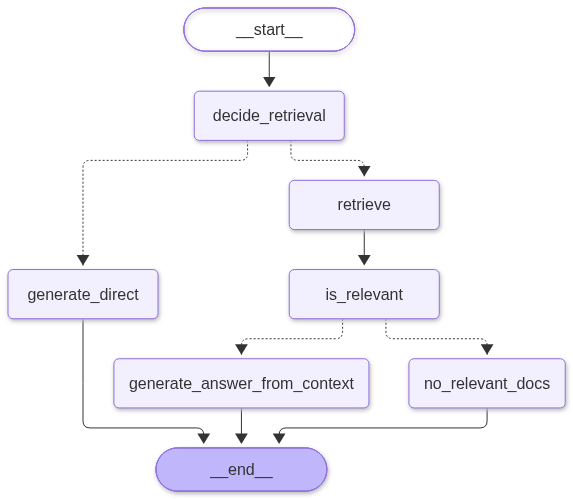

In [25]:
app = graph.compile()

app

In [26]:
result = app.invoke(
    {
        "question": "Who is the CEO of the company?",
        "need_retrieval": False,
        "docs": [],
        "answer": "",
    }
)

In [28]:
print(result["answer"][0]['text'])

Based on the provided document, the Chief Executive Officer (CEO) and Founder of the company is Ishaan Deshpande.


In [29]:
result = app.invoke(
    {
        "question": "What is the stock price of this company?",
        "need_retrieval": False,
        "docs": [],
        "answer": "",
    }
)

In [35]:
for doc in result["docs"]:
    print(doc.page_content)
    print("--"*50)

Meridian Freight Technologies
Product Catalogue and Pricing Guide
Internal document - fictional content for testing purposes
Page 2
Feature
Launch
Scale
Enterprise
Price
INR 450 per vehicle per
month
INR 780 per vehicle per month
Custom quote
Minimum fleet size
10 vehicles
50 vehicles
300 vehicles
Products included
FleetPulse (basic)
FleetPulse, RouteMind,
ShipSense
All five products
Trip history
3 months
12 months
36 months
API access
No
Read-only API
Full API and webhooks
Support
Email, business hours
Email and chat, extended
hours
24x7 with named manager
Uptime commitment
99.5%
99.9%
99.95%
----------------------------------------------------------------------------------------------------
Meridian Freight Technologies
Product Catalogue and Pricing Guide
Internal document - fictional content for testing purposes
Page 1
Product Catalogue and Pricing Guide
Five products, three plans, simple per-vehicle pricing | Price list valid from 1 July 2026
About this dataset: Meridian Freight Te

In [30]:
print(result["relevant_docs"])

[]


In [31]:
print(result["context"])

In [32]:
print(result["answer"])

No relevant document found.
